# Phase 1: Data Exploration and Preprocessing

# 1. Introduction & Problem Statement

### Domain: Financial Risk and Credit Risk

Credit card default is an important problem in the financial domain because it can cause financial losses for banks. Financial institutions need to assess the risk associated with their clients and identify those who may fail to make their credit card payments. However, evaluating credit risk requires analyzing different factors related to clients' financial behavior and repayment history.

In this project, we use the Default of Credit Card Clients dataset, which contains information about 30,000 clients in Taiwan, including credit limits, demographic information, repayment status, bill amounts, and previous payments.

This notebook focuses on exploring and understanding the dataset through exploratory data analysis (EDA). It also documents the data preprocessing steps required to prepare the data for supervised machine learning.

The overall project aims to develop a machine learning-based decision-support tool for credit-risk assessment. Such a tool could help credit-risk managers identify clients who may be at higher risk of default and support decisions such as reviewing credit limits, contacting clients, and prioritizing follow-up. The dataset exploration and preprocessing in this notebook provide the foundation for the supervised learning and model evaluation conducted in `Phase1_Supervised_Learning.ipynb`.

# 2. Dataset Selection & Justification

We selected the **Default of Credit Card Clients** dataset from Kaggle. It contains information about 30,000 clients in Taiwan, including credit limits, demographic information, repayment status, bill amounts, and previous payments.

### Dataset Justification

**1. Relevance**

The dataset is relevant to the financial risk domain because it contains information that can be used to investigate patterns associated with credit card default. The target variable, `default.payment.next.month`, makes the dataset suitable for a binary classification task, where the goal is to predict whether a client will default on their payment next month.

**2. Completeness**

The dataset contains 30,000 records and 23 input features, excluding the `ID` and target columns. This provides a substantial number of records and multiple features for exploratory data analysis and supervised machine learning.

**3. Quality**

The dataset contains structured numerical and categorical features that can be analyzed using Python. Before preprocessing, we will examine missing values, duplicate records, unusual category codes, and potential outliers to identify data quality issues and determine which preprocessing steps are appropriate.

**Dataset Source:** [Kaggle | Default of Credit Card Clients](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset)

**Original Dataset Source:** [UCI Machine Learning Repository | Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default%2Bof%2Bcredit%2Bcard%2Bclients)

# 3. Initial Data Inspection

In this section, we check the dataset to understand its structure and look for any missing values, duplicated rows, or unusual values before preparing the data for machine learning.


3.1 Load Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "Dataset/raw_kaggle_data.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


3.2 Dataset Structure and Summary Statistics

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [ ]:
print("\nSummary statistics for numerical columns:")
display(df.describe())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [4]:
columns_to_check = [
    "AGE",
    "LIMIT_BAL",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

print("\nDetailed statistics for selected columns:")
display(df[columns_to_check].describe().round(2))



Detailed statistics for selected columns:


,AGE,LIMIT_BAL,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,35.49,167484.32,5663.58,5921.16,5225.68,4826.08,4799.39,5215.50
std,9.22,129747.66,16563.28,23040.87,17606.96,15666.16,15278.31,17777.47
min,21.00,10000.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,28.00,50000.00,1000.00,833.00,390.00,296.00,252.50,117.75
50%,34.00,140000.00,2100.00,2009.00,1800.00,1500.00,1500.00,1500.00
75%,41.00,240000.00,5006.00,5000.00,4505.00,4013.25,4031.50,4000.00
max,79.00,1000000.00,873552.00,1684259.00,896040.00,621000.00,426529.00,528666.00


3.3 Data Quality Checks

In [ ]:
# Check missing values and duplicate rows
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values: 0
Duplicate rows: 0


In [6]:
# Inspect categorical values
for col in ["EDUCATION", "MARRIAGE", "SEX"]:
    print(f"\n{col} values:")
    print(sorted(df[col].unique()))


EDUCATION values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

MARRIAGE values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

SEX values:
[np.int64(1), np.int64(2)]


In [7]:
# Check ID uniqueness and range
print("\nNumber of unique IDs:", df["ID"].nunique())
print("Number of rows:", len(df))
print("Duplicate IDs:", df["ID"].duplicated().sum())
print("Minimum ID:", df["ID"].min())
print("Maximum ID:", df["ID"].max())

# Check whether IDs cover the expected range
expected_ids = set(range(1, 30001))
actual_ids = set(df["ID"])

print("Missing IDs:", len(expected_ids - actual_ids))
print("Unexpected IDs:", sorted(actual_ids - expected_ids))


Number of unique IDs: 30000
Number of rows: 30000
Duplicate IDs: 0
Minimum ID: 1
Maximum ID: 30000
Missing IDs: 0
Unexpected IDs: []


3.4 Target Variable Inspection

In [8]:
target = "default.payment.next.month"

print("Target class counts:")
print(df[target].value_counts().sort_index())

print("\nTarget class percentages:")
print((df[target].value_counts(normalize=True).sort_index() * 100).round(2))


Target class counts:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Target class percentages:
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


3.5 Repayment Status (PAY) Inspection

In [9]:
pay_columns = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

for col in pay_columns:
    print(f"\n{col} value counts:")
    print(df[col].value_counts().sort_index())


PAY_0 value counts:
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2 value counts:
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3 value counts:
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

PAY_4 value counts:
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

PAY_5 value counts:
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64

PAY_6 value counts:
PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184


3.6 Bill Amount (BILL_AMT) Inspection

In [10]:
bill_columns = [
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"
]

# Check negative bill amounts
print("Negative values in bill amount columns:")
for col in bill_columns:
    print(f"{col}: {(df[col] < 0).sum()}")

Negative values in bill amount columns:
BILL_AMT1: 590
BILL_AMT2: 669
BILL_AMT3: 655
BILL_AMT4: 675
BILL_AMT5: 655
BILL_AMT6: 688


In [11]:
# Summary statistics
print("\nSummary statistics for bill amounts:")
display(df[bill_columns].describe().round(2))


Summary statistics for bill amounts:


,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,51223.33,49179.08,47013.15,43262.95,40311.40,38871.76
std,73635.86,71173.77,69349.39,64332.86,60797.16,59554.11
min,-165580.00,-69777.00,-157264.00,-170000.00,-81334.00,-339603.00
25%,3558.75,2984.75,2666.25,2326.75,1763.00,1256.00
50%,22381.50,21200.00,20088.50,19052.00,18104.50,17071.00
75%,67091.00,64006.25,60164.75,54506.00,50190.50,49198.25
max,964511.00,983931.00,1664089.00,891586.00,927171.00,961664.00


In [12]:
# Detect potential outliers using the IQR method
print("\nPotential outliers using the IQR method:")
for col in bill_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {outliers}")


Potential outliers using the IQR method:
BILL_AMT1: 2400
BILL_AMT2: 2395
BILL_AMT3: 2469
BILL_AMT4: 2622
BILL_AMT5: 2725
BILL_AMT6: 2693


3.7 Numerical and Categorical Features

The dataset contains numerical and categorical features. Numerical features represent quantities, such as credit limits, ages, bill amounts, and payment amounts. Categorical features represent groups or encoded categories. The `PAY` features represent repayment status codes with an order related to payment delay. Since some categorical features are encoded using numbers, their data types alone do not determine their meaning.

In [ ]:

target = "default.payment.next.month"
id_column = "ID"

numerical_features = [
    "LIMIT_BAL", "AGE",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

categorical_features = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))
print("Target variable:", target)
print("ID excluded from features:", id_column)

Number of numerical features: 14
Number of categorical features: 9
Target variable: default.payment.next.month
ID excluded from features: ID


## Initial Inspection Findings

#### Dataset Overview

- The dataset contains 30,000 rows and 25 columns. The target variable, `default.payment.next.month`, indicates whether a client defaults on their credit card payment in the following month.
- The dataset contains 14 numerical features and 9 categorical features. The `ID` column and target variable are excluded from the 23 input features.

#### Data Quality

- No missing values or fully duplicated rows were found.
- All 30,000 records have unique IDs, covering the expected range from 1 to 30,000.
- The `ID` column will be excluded from model training because it serves as a client identifier rather than a predictive feature.
- The `EDUCATION` variable contains values from 0 to 6, and `MARRIAGE` contains values from 0 to 3. These category codes require further review before preprocessing.
- The `BILL_AMT` columns contain negative values, ranging from 590 to 688 records per column. The IQR method identified between 2,395 and 2,725 potential outliers in each column. These values require further investigation before deciding how to handle them.

#### Target Distribution

- **0 (No default):** 23,364 clients (77.88%).
- **1 (Default):** 6,636 clients (22.12%).

The target classes are imbalanced, with the no-default class representing 77.88% of the dataset. Therefore, model evaluation should consider precision, recall, and F1-score in addition to accuracy.

#### Conclusion

The dataset is suitable for binary classification. The initial checks found no missing values, duplicate rows, or ID inconsistencies. However, the categorical codes, negative bill amounts, and potential outliers require further investigation during exploratory data analysis and preprocessing.

## Train/Test Split

The dataset is split into training (80%) and test (20%) sets before model training and preprocessing. A stratified split is used to preserve the proportion of default and non-default clients in both sets.

The training set is used for exploratory analysis that informs preprocessing decisions and for fitting preprocessing transformations. The test set is kept separate for final model evaluation to help prevent data leakage.

In [13]:

target = "default.payment.next.month"

X = df.drop(columns=[target, "ID"])
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.dtypes)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

X shape: (30000, 23)
y shape: (30000,)
LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
PAY_0          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
dtype: object
Training set: (24000, 23)
Test set: (6000, 23)


# 4. Exploratory Data Analysis (EDA)

In this section, we explore the dataset using visualizations and statistical analysis to understand the distribution of features, identify patterns, and examine relationships between the input features and the target variable.


### 4.1 Data Quality Review



In [ ]:
eda_train = X_train.copy()
eda_train[target] = y_train

print("Missing values:", eda_train.isna().sum().sum())
print("Duplicate rows (excluding ID):", eda_train.duplicated().sum())

Missing values: 0
Duplicate rows (excluding ID): 26


In [ ]:
duplicate_rows = eda_train[
    eda_train.duplicated(keep=False)
]

display(duplicate_rows.head(10))

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
26249,90000.0,2,1,2,31,1,-2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
29265,180000.0,1,2,1,26,-1,-1,-1,-1,-1,...,396.0,396.0,396.0,396.0,396.0,396.0,396.0,396.0,396.0,0
9407,160000.0,1,2,2,28,-2,-2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
18,360000.0,2,1,1,49,1,-2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2621,210000.0,2,1,2,39,1,-2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
19114,80000.0,2,2,1,31,-2,-2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
13912,140000.0,1,1,2,29,1,-2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
29909,360000.0,1,1,2,32,-2,-2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
26805,300000.0,1,1,2,27,-2,-2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
22726,90000.0,2,1,2,31,1,-2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


The training set has no missing values. There are 26 repeated rows when ID is excluded; these are examined above.

### 4.2 Target Variable Distribution


In [ ]:
target_summary = pd.DataFrame({
    "Count": eda_train[target].value_counts(),
    "Percentage (%)": eda_train[target].value_counts(normalize=True) * 100
}).sort_index()

target_summary.index.name = "Default (0 = No, 1 = Yes)"
display(target_summary.round(2))

,Count,Percentage (%)
"Default (0 = No, 1 = Yes)",,
0,18691,77.88
1,5309,22.12


The training set contains 18,691 non-default clients (77.88%) and 5,309 default clients (22.12%). This class imbalance means that accuracy alone is insufficient; recall, precision, and F1-score should also be considered.

### 4.3 Numerical Features

In [ ]:
numeric_summary = eda_train[numerical_features].describe().T
numeric_summary["skewness"] = eda_train[numerical_features].skew()

display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness
LIMIT_BAL,24000.0,167364.67,129511.31,10000.0,50000.00,140000.0,240000.00,1000000.0,1.00
AGE,24000.0,35.43,9.20,21.0,28.00,34.0,41.00,75.0,0.74
BILL_AMT1,24000.0,51100.50,73510.03,-165580.0,3513.75,22330.0,66966.50,964511.0,2.69
BILL_AMT2,24000.0,49012.27,70840.10,-69777.0,2989.75,21107.0,63992.75,983931.0,2.73
BILL_AMT3,24000.0,46861.88,68403.93,-61506.0,2652.00,20031.0,60033.75,855086.0,2.73
BILL_AMT4,24000.0,43156.66,64046.73,-81334.0,2332.00,19004.5,54386.50,891586.0,2.82
BILL_AMT5,24000.0,40164.41,60627.85,-81334.0,1746.00,18102.5,50142.25,927171.0,2.92
BILL_AMT6,24000.0,38675.98,59308.74,-339603.0,1225.00,16993.0,48977.25,961664.0,2.88
PAY_AMT1,24000.0,5623.56,16148.32,0.0,1000.00,2100.5,5018.25,873552.0,15.31
PAY_AMT2,24000.0,5879.97,20252.98,0.0,840.00,2014.0,5000.00,1215471.0,21.12


The mean age is 35.43 years, with a median of 34. Payment amounts are strongly right-skewed, with means substantially higher than medians. Therefore, medians and quartiles are useful alongside means when describing these features. Extreme values require review rather than automatic removal.

### 4.4 Categorical Features

In [ ]:
for feature in categorical_features:
    summary = pd.DataFrame({
        "Count": eda_train[feature].value_counts(),
        "Percentage (%)": (
            eda_train[feature].value_counts(normalize=True) * 100
        )
    }).sort_index()

    print(f"\n{feature}")
    display(summary.round(2))


SEX


,Count,Percentage (%)
SEX,,
1,9486,39.52
2,14514,60.48



EDUCATION


,Count,Percentage (%)
EDUCATION,,
0,12,0.05
1,8455,35.23
2,11256,46.90
3,3903,16.26
4,97,0.40
5,235,0.98
6,42,0.18



MARRIAGE


...

,Count,Percentage (%)
PAY_4,,
-2,3477,14.49
-1,4531,18.88
0,13180,54.92
1,2,0.01
2,2542,10.59
3,143,0.60
4,53,0.22
5,28,0.12
6,3,0.01



PAY_5


,Count,Percentage (%)
PAY_5,,
-2,3659,15.25
-1,4417,18.40
0,13560,56.50
2,2102,8.76
3,142,0.59
4,65,0.27
5,13,0.05
6,3,0.01
7,38,0.16



PAY_6


,Count,Percentage (%)
PAY_6,,
-2,3942,16.42
-1,4576,19.07
0,13008,54.20
2,2230,9.29
3,149,0.62
4,42,0.18
5,8,0.03
6,11,0.05
7,33,0.14


SEX category 2 represents 60.48% of the training set. EDUCATION category 2 is the most common (46.90%), while MARRIAGE category 2 accounts for 53.36%. EDUCATION codes 0, 5, and 6, and MARRIAGE code 0 require checking against the dataset documentation before deciding how to handle them. Repayment-status code 0 is the most frequent across all six months. Rare categories should be interpreted cautiously because their sample sizes are small.

### 4.5 Feature vs Target Analysis

In [ ]:
for feature in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0"]:
    comparison = eda_train.groupby(feature)[target].agg(
        Count="size",
        Defaults="sum",
        Default_Rate="mean"
    )
    comparison["Default_Rate"] *= 100
    comparison = comparison.rename(
        columns={"Default_Rate": "Default Rate (%)"}
    )

    print(f"\n{feature}")
    display(comparison.round(2))


SEX


,Count,Defaults,Default Rate (%)
SEX,,,
1,9486,2312,24.37
2,14514,2997,20.65



EDUCATION


,Count,Defaults,Default Rate (%)
EDUCATION,,,
0,12,0,0.00
1,8455,1631,19.29
2,11256,2674,23.76
3,3903,976,25.01
4,97,6,6.19
5,235,15,6.38
6,42,7,16.67



MARRIAGE


,Count,Defaults,Default Rate (%)
MARRIAGE,,,
0,47,5,10.64
1,10892,2538,23.30
2,12806,2694,21.04
3,255,72,28.24



PAY_0


,Count,Defaults,Default Rate (%)
PAY_0,,,
-2,2198,279,12.69
-1,4527,753,16.63
0,11781,1508,12.80
1,3000,1031,34.37
2,2138,1483,69.36
3,245,188,76.73
4,58,38,65.52
5,18,8,44.44
6,10,6,60.00


Default rates differ across demographic categories: SEX category 1 has a higher rate (24.37%) than category 2 (20.65%). PAY_0 shows substantial differences, with default rates of 12.80% for code 0 and 69.36% for code 2. This suggests a useful association with the target, although predictive importance requires model-based validation. Rates for rare categories should be interpreted cautiously.

In [ ]:
numeric_by_target = (
    eda_train.groupby(target)[numerical_features]
    .agg(["mean", "median"])
    .T
)

numeric_by_target.columns = ["No Default", "Default"]
display(numeric_by_target.round(2))

No Default    Default
LIMIT_BAL mean     178476.91  128242.61
          median   150000.00   90000.00
AGE       mean         35.37      35.65
          median       34.00      34.00
BILL_AMT1 mean      51990.60   47966.81
          median    23051.00   20439.00
BILL_AMT2 mean      49693.66   46613.35
          median    21524.00   20347.00
BILL_AMT3 mean      47528.29   44515.71
          median    20112.00   19839.00
BILL_AMT4 mean      43625.19   41507.16
          median    18957.00   19111.00
BILL_AMT5 mean      40478.14   39059.88
          median    17990.00   18470.00
BILL_AMT6 mean      38934.45   37765.99
          median    16544.00   18134.00
PAY_AMT1  mean       6255.60    3398.37
          median     2471.00    1616.00
PAY_AMT2  mean       6582.41    3406.97
          median     2263.00    1563.00
PAY_AMT3  mean       5718.52    3445.81
          median     2000.00    1214.00
PAY_AMT4  mean       5234.30    3227.29
          median     1741.00    1000.00
PAY_AMT5  mean       5191.87    3284.49
          median     1792.00    1000.00
PAY_AMT6  mean       5736.77    3445.43
          median     1703.00    1000.00

Default clients have a lower median credit limit (90,000) than non-default clients (150,000). Their mean and median payment amounts are also lower across all six months. Both groups have a median age of 34 years. These descriptive differences indicate potential associations with default, but do not establish causation or predictive importance.

### 4.6 Correlation Analysis

In [ ]:
numeric_corr = eda_train[
    numerical_features + [target]
].corr()

target_corr = (
    numeric_corr[target]
    .drop(target)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

display(target_corr.rename("Correlation with Target").round(3))

LIMIT_BAL   -0.161
PAY_AMT1    -0.073
PAY_AMT2    -0.065
PAY_AMT4    -0.055
PAY_AMT3    -0.054
PAY_AMT6    -0.053
PAY_AMT5    -0.053
BILL_AMT1   -0.023
BILL_AMT3   -0.018
BILL_AMT2   -0.018
BILL_AMT4   -0.014
AGE          0.013
BILL_AMT5   -0.010
BILL_AMT6   -0.008
Name: Correlation with Target, dtype: float64

LIMIT_BAL has the largest absolute Pearson correlation with the target among numerical features (-0.161), indicating a weak negative linear association. Payment amounts also show weak negative correlations, while age and bill amounts have correlations close to zero. Low Pearson correlation alone does not justify removing a feature, as nonlinear relationships and interactions may still be useful.

In [ ]:
feature_corr = eda_train[numerical_features].corr()

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

correlated_pairs = (
    upper_triangle.stack()
    .rename("Correlation")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

display(correlated_pairs[correlated_pairs.abs() >= 0.8].round(3))

BILL_AMT1  BILL_AMT2    0.952
BILL_AMT5  BILL_AMT6    0.946
BILL_AMT4  BILL_AMT5    0.941
BILL_AMT2  BILL_AMT3    0.938
BILL_AMT3  BILL_AMT4    0.933
BILL_AMT4  BILL_AMT6    0.901
BILL_AMT1  BILL_AMT3    0.901
BILL_AMT2  BILL_AMT4    0.895
BILL_AMT3  BILL_AMT5    0.892
BILL_AMT1  BILL_AMT4    0.862
BILL_AMT2  BILL_AMT5    0.861
BILL_AMT3  BILL_AMT6    0.857
BILL_AMT2  BILL_AMT6    0.832
BILL_AMT1  BILL_AMT5    0.830
           BILL_AMT6    0.803
Name: Correlation, dtype: float64

Bill amounts across the six months are highly correlated, with pairwise correlations ranging from 0.803 to 0.952. This suggests potential redundancy. All six features are retained initially; any reduced feature set should be compared with the full set using cross-validation on the training data.

### 4.7 EDA Summary and Feature Selection Recommendations

- EDA was conducted on the training set only.
- No missing values were found. There are 26 repeated rows when ID is excluded; these are retained because matching profiles alone do not prove duplicate client records.
- The target is imbalanced: 77.88% non-default and 22.12% default.
- Payment amounts are strongly right-skewed; medians and quartiles complement means.
- PAY_0 shows substantial differences in default rates across categories.
- Default clients have lower median credit limits and lower payment amounts.
- Numerical features have weak Pearson correlations with the target. This alone does not justify removing them.
- Bill amounts are highly correlated with one another and are candidates for a feature-reduction experiment.
- ID remains excluded from model inputs. SEX and MARRIAGE are excluded in Section 5.1 to avoid directly using gender and marital status in prediction. Their exclusion does not guarantee fairness. All other predictors are retained.
- Undocumented EDUCATION codes are retained as separate categories. Rare categories and extreme values are not removed automatically.

#### Cleaning Decisions

- No missing values were detected in the training set; no imputation is needed.
- The 26 repeated rows excluding ID are retained because identical profiles do not establish that they belong to the same client.
- EDUCATION codes 0, 5, and 6 and MARRIAGE code 0 are not defined in the original UCI description. The EDUCATION codes are retained as separate categories without assigning unsupported meanings, while MARRIAGE is excluded in Section 5.1 to avoid directly using marital status in prediction.
- Repayment-status codes are retained without automatic recoding.
- Negative bill amounts and extreme monetary values are retained because they have not been confirmed as data errors.
- ID is already excluded from model inputs.
- The original dataset is preserved. Categorical encoding and scaling will be handled in the preprocessing pipeline.

Source: [UCI dataset documentation](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)

### 4.8 Visual Exploratory Analysis

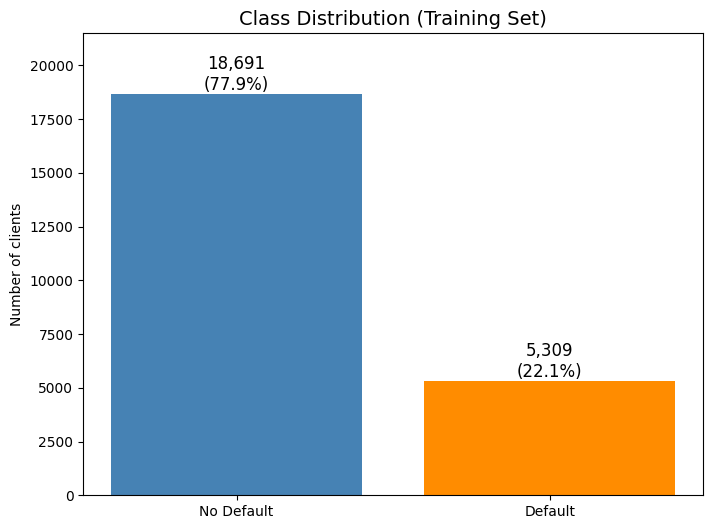

In [ ]:
import matplotlib.pyplot as plt

counts = eda_train[target].value_counts().sort_index()

plt.figure(figsize=(8, 6))
plt.bar(["No Default", "Default"], counts.values, color=["steelblue", "darkorange"])
plt.title("Class Distribution (Training Set)", fontsize=14)
plt.ylabel("Number of clients")
plt.ylim(0, counts.max() * 1.15)

for i, v in enumerate(counts.values):
    plt.text(i, v, f"{v:,}\n({v/counts.sum()*100:.1f}%)", ha="center", va="bottom", fontsize=12)

plt.show()

**Interpretation:**

The plot shows the number of clients in each class in the training set:
- **No Default (0):** 18,691 clients (77.88%)
- **Default (1):** 5,309 clients (22.12%)

The dataset is imbalanced, since non-default clients are about 3.5 times more than default clients.

This matters for model evaluation. A model that predicts "No Default" for every client would reach about 78% accuracy, but it would not detect any client who actually defaults, which is the main goal of the system. Therefore, accuracy alone is not enough, and we will also use **precision, recall, and F1-score**, focusing on the Default class.

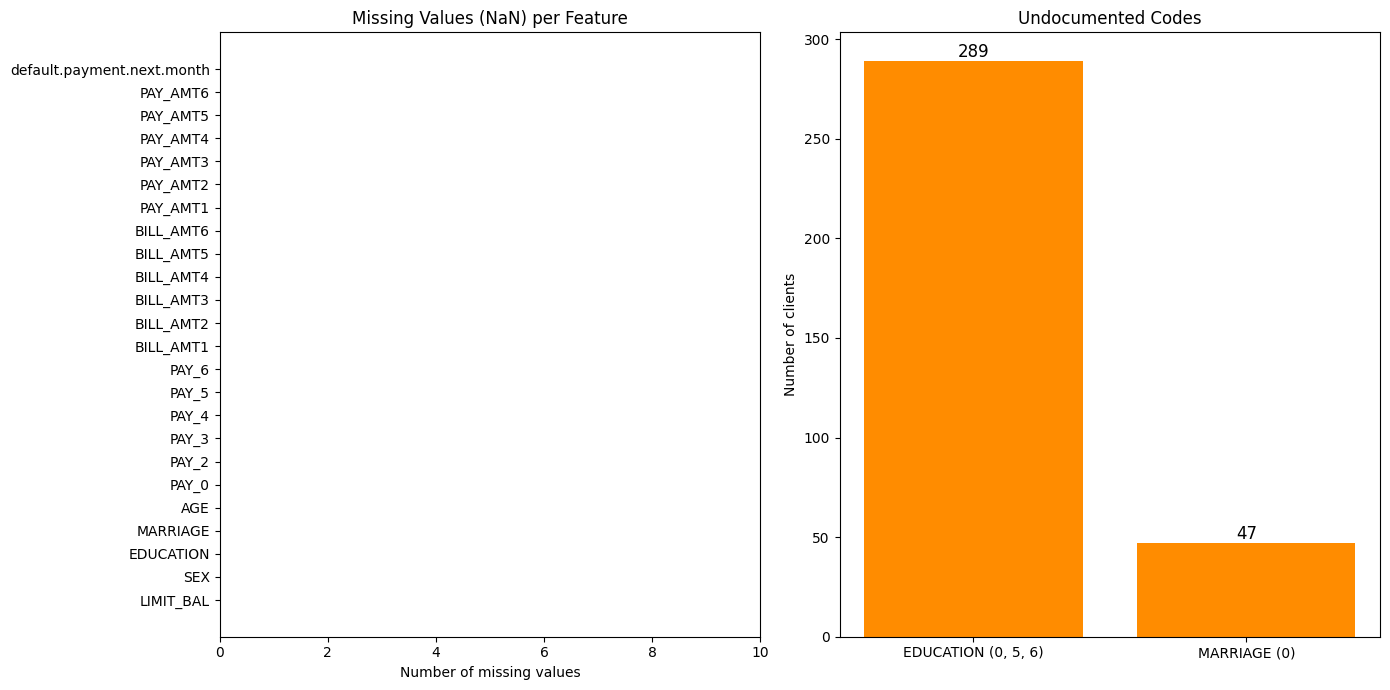

In [ ]:
missing = eda_train.isnull().sum()

strange_codes = {
    "EDUCATION (0, 5, 6)": eda_train["EDUCATION"].isin([0, 5, 6]).sum(),
    "MARRIAGE (0)": (eda_train["MARRIAGE"] == 0).sum()
}

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].barh(missing.index, missing.values, color="steelblue")
axes[0].set_title("Missing Values (NaN) per Feature")
axes[0].set_xlabel("Number of missing values")
axes[0].set_xlim(0, 10)

axes[1].bar(strange_codes.keys(), strange_codes.values(), color="darkorange")
axes[1].set_title("Undocumented Codes")
axes[1].set_ylabel("Number of clients")
for i, v in enumerate(strange_codes.values()):
    axes[1].text(i, v, str(v), ha="center", va="bottom", fontsize=12)

plt.tight_layout()
plt.show()

**Interpretation:**

The left plot shows that **none of the features contain missing values (NaN)**, so no imputation is needed.

However, all features were also checked for values that are not defined in the original UCI documentation:
- **EDUCATION** has codes 0, 5, and 6 for 289 clients (about 1.2%), and **MARRIAGE** has code 0 for 47 clients (about 0.2%). Their meaning is unknown, so they act as a hidden form of missing information (right plot).
- The repayment-status features (**PAY_0 to PAY_6**) also use codes -2 and 0, which are not in the documentation. However, they are very common (around half of the clients) and are generally understood as "no credit use" and "minimum payment made", so they are treated as normal categories, not missing data.
- **Negative bill amounts** (BILL_AMT) are not missing values; they mean the client paid more than the bill. They are discussed in the distribution analysis.
- All other features (**SEX, AGE, LIMIT_BAL, PAY_AMT**) contain only valid values.

Since the unknown codes affect a very small share of clients, the EDUCATION codes are kept as separate categories, as decided in the cleaning step, instead of being removed or given an unsupported meaning.

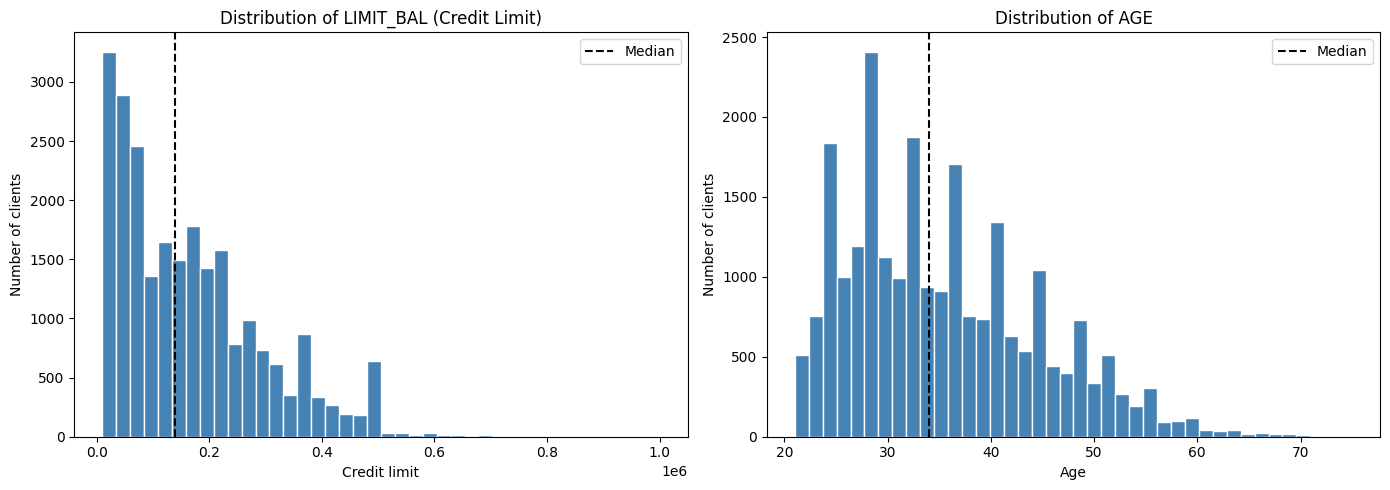

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(eda_train["LIMIT_BAL"], bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(eda_train["LIMIT_BAL"].median(), color="black", linestyle="--", label="Median")
axes[0].set_title("Distribution of LIMIT_BAL (Credit Limit)")
axes[0].set_xlabel("Credit limit")
axes[0].set_ylabel("Number of clients")
axes[0].legend()

axes[1].hist(eda_train["AGE"], bins=40, color="steelblue", edgecolor="white")
axes[1].axvline(eda_train["AGE"].median(), color="black", linestyle="--", label="Median")
axes[1].set_title("Distribution of AGE")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Number of clients")
axes[1].legend()

plt.tight_layout()
plt.show()

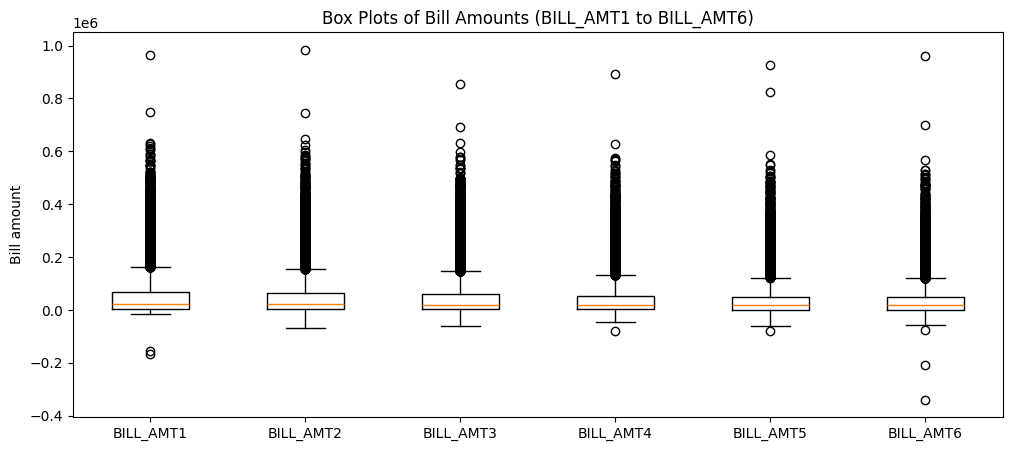

In [ ]:
plt.figure(figsize=(12, 5))
plt.boxplot([eda_train[col] for col in bill_columns], tick_labels=bill_columns)
plt.title("Box Plots of Bill Amounts (BILL_AMT1 to BILL_AMT6)")
plt.ylabel("Bill amount")
plt.show()

**Interpretation:**

**LIMIT_BAL:** Most clients have relatively low credit limits, with a median of 140,000, while a small number have limits up to 1,000,000. The distribution is right-skewed.

**AGE:** Most clients are between 25 and 40 years old, with a median of 34. The distribution is slightly right-skewed, with fewer clients at older ages.

**BILL_AMT1 to BILL_AMT6:** The boxes are compressed near zero because most bills are small, while many outliers reach close to 1,000,000. Some bills are negative, which means the client paid more than the bill amount. These values are kept because they are realistic and not confirmed errors.

**Implication for preprocessing:** The numerical features are on very different scales (age in tens, amounts in hundreds of thousands) and several are highly skewed. Models that are sensitive to scale, such as SVM, will need **feature scaling**, and a **log transformation** of the monetary features could reduce the effect of extreme values.

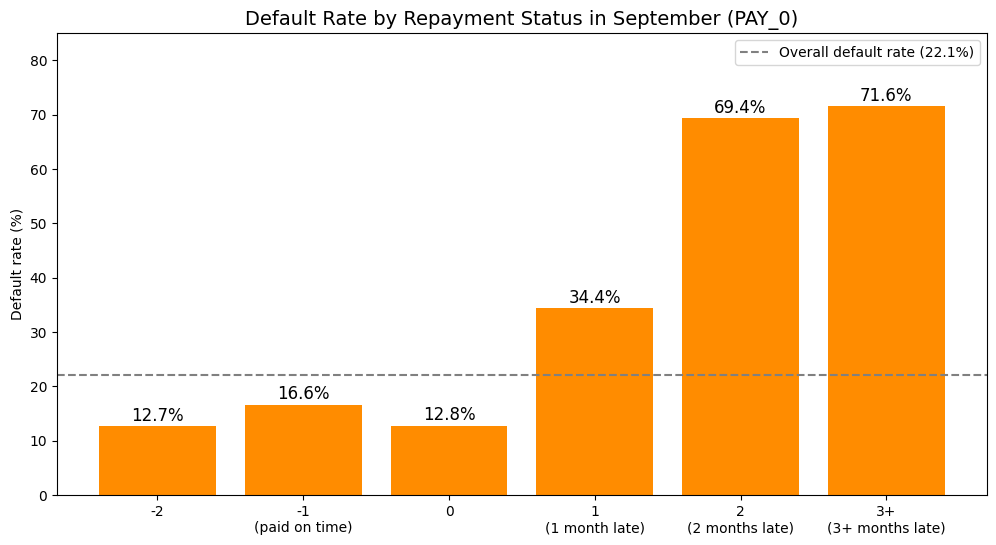

In [ ]:
pay0_grouped = eda_train["PAY_0"].clip(upper=3)

default_rate = eda_train.groupby(pay0_grouped)[target].mean() * 100

labels = ["-2", "-1\n(paid on time)", "0",
          "1\n(1 month late)", "2\n(2 months late)",
          "3+\n(3+ months late)"]

plt.figure(figsize=(12, 6))
plt.bar(labels, default_rate.values, color="darkorange")

overall = eda_train[target].mean() * 100
plt.axhline(overall, color="gray", linestyle="--", label=f"Overall default rate ({overall:.1f}%)")

for i, v in enumerate(default_rate.values):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=12)

plt.title("Default Rate by Repayment Status in September (PAY_0)", fontsize=14)
plt.ylabel("Default rate (%)")
plt.ylim(0, 85)
plt.legend()
plt.show()

**Interpretation:**

The plot shows the default rate for each repayment status in September (PAY_0), the most recent month before the prediction.

- Clients with PAY_0 codes -2, -1, and 0 have default rates of approximately 13–17%. The meanings of codes -2 and 0 are not defined in the original documentation.
- The default rate rises sharply once a payment is delayed: **34.4%** for a 1-month delay, **69.4%** for a 2-month delay, and **71.6%** for a delay of 3 months or more.

This means that clients who are 2 or more months late are about **4 times more likely** to default than clients who paid on time. Therefore, **PAY_0 is expected to be one of the strongest predictors** of default. Delays of 3 months or more were grouped together in this plot because each of those codes contains very few clients.

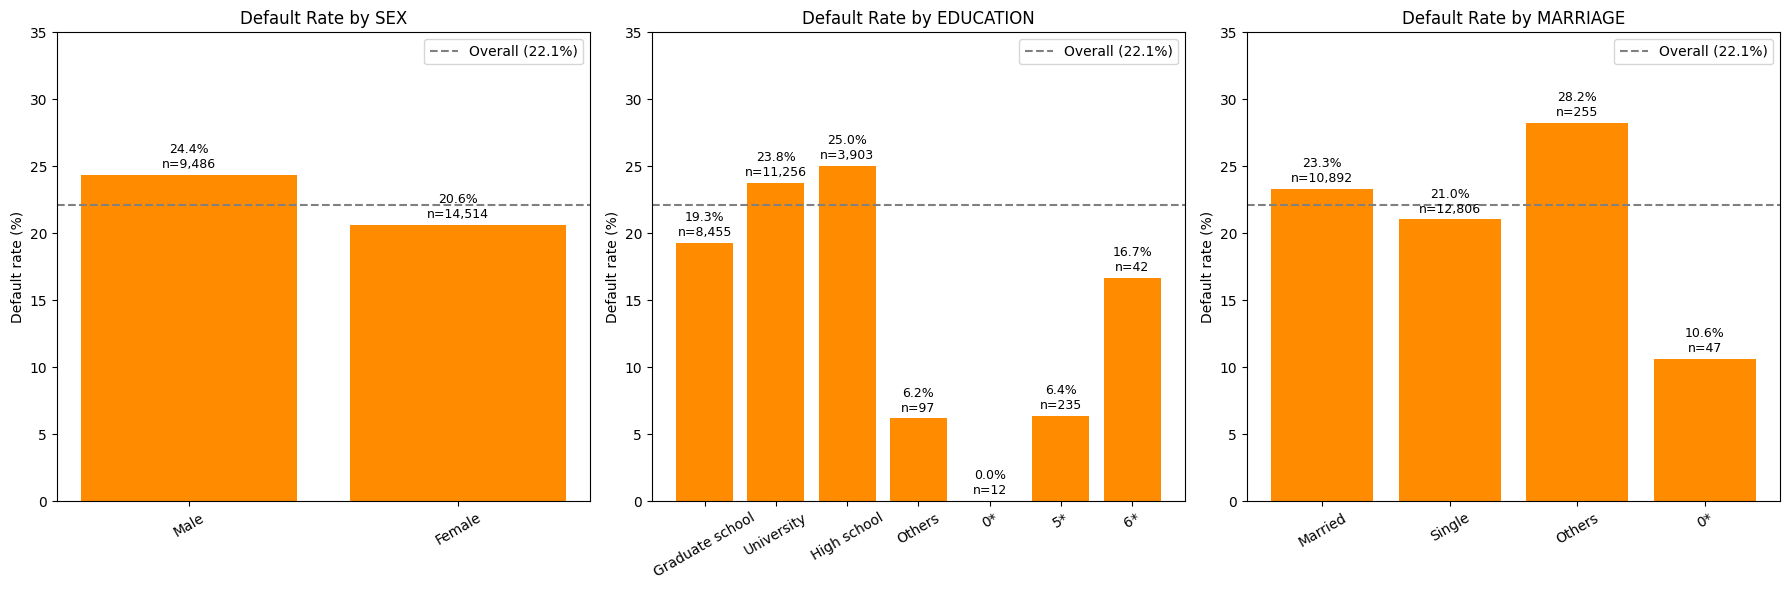

In [ ]:
def plot_default_rate(ax, column, names, title):
    groups = eda_train[column].map(names)
    rate = eda_train.groupby(groups)[target].mean() * 100
    count = groups.value_counts()
    rate = rate.reindex(list(dict.fromkeys(names.values())))

    ax.bar(rate.index, rate.values, color="darkorange")
    ax.axhline(overall, color="gray", linestyle="--", label=f"Overall ({overall:.1f}%)")
    for i, (name, v) in enumerate(rate.items()):
        ax.text(i, v + 0.5, f"{v:.1f}%\nn={count[name]:,}", ha="center", fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("Default rate (%)")
    ax.set_ylim(0, 35)
    ax.tick_params(axis="x", rotation=30)
    ax.legend()

sex_names = {1: "Male", 2: "Female"}
edu_names = {1: "Graduate school", 2: "University", 3: "High school", 4: "Others",
             0: "0*", 5: "5*", 6: "6*"}
mar_names = {1: "Married", 2: "Single", 3: "Others", 0: "0*"}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
plot_default_rate(axes[0], "SEX", sex_names, "Default Rate by SEX")
plot_default_rate(axes[1], "EDUCATION", edu_names, "Default Rate by EDUCATION")
plot_default_rate(axes[2], "MARRIAGE", mar_names, "Default Rate by MARRIAGE")
plt.tight_layout()
plt.show()

**Interpretation:**

The plots compare the default rate across demographic groups:

- **SEX:** Male clients have a slightly higher default rate (**24.4%**) than female clients (**20.6%**).
- **EDUCATION:** The default rate increases slightly as education level decreases: **19.3%** for graduate school, **23.8%** for university, and **25.0%** for high school.
- **MARRIAGE:** Married clients (**23.3%**) and single clients (**21.0%**) have similar default rates.

For the main groups, all rates stay close to the overall rate of 22.1%, with differences of only a few percentage points. This is much weaker than the effect of repayment status (PAY_0), where the rate ranged from about 13% to 72%. Therefore, **demographic features are expected to be weak predictors** compared to payment behavior.

The undocumented codes (marked with *) and the "Others" groups contain very few clients (for example, only 12 clients have EDUCATION = 0), so their rates are not reliable and should not be interpreted.

**Ethical note:** Even if SEX or MARRIAGE showed a stronger effect, using them to make credit decisions could be unfair to certain groups. This should be considered when choosing the final features.

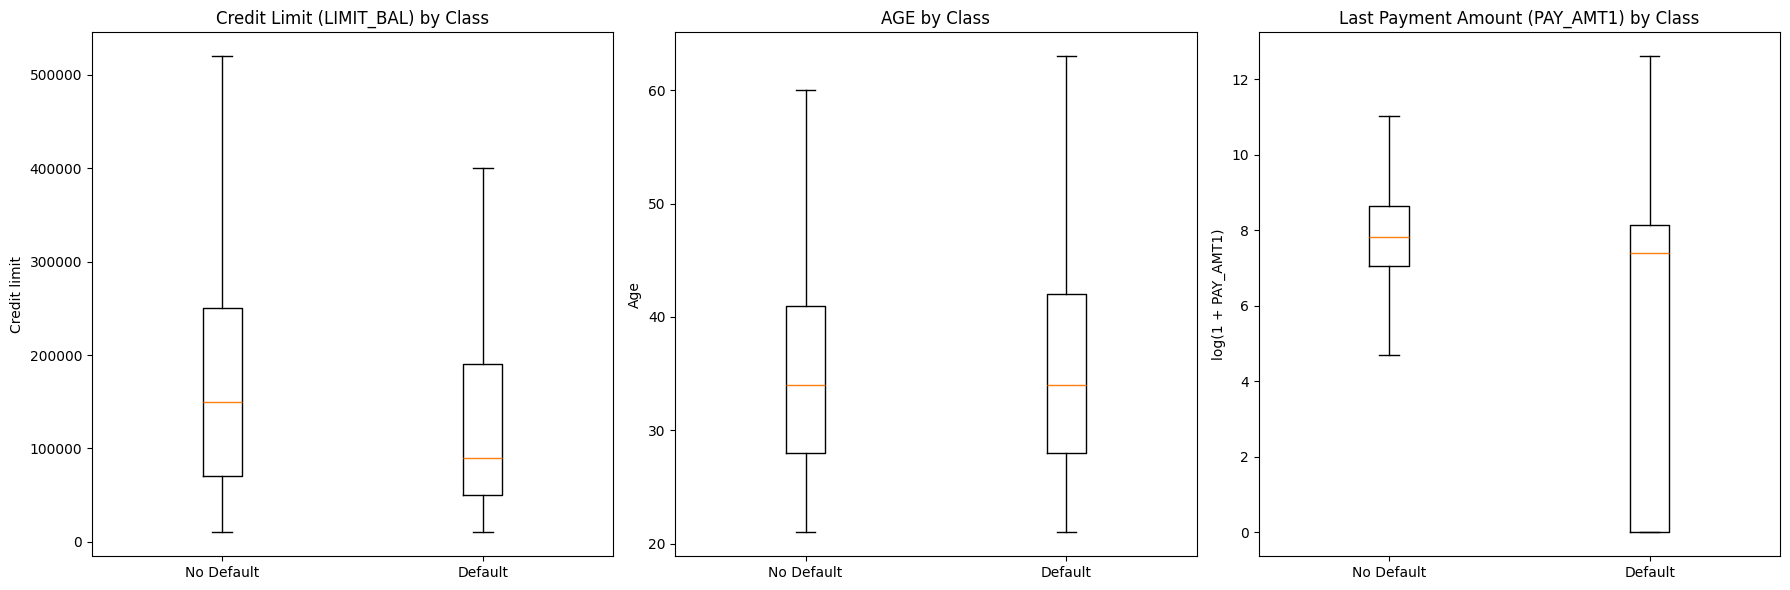

In [ ]:
no_default = eda_train[eda_train[target] == 0]
default = eda_train[eda_train[target] == 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].boxplot([no_default["LIMIT_BAL"], default["LIMIT_BAL"]],
                tick_labels=["No Default", "Default"], showfliers=False)
axes[0].set_title("Credit Limit (LIMIT_BAL) by Class")
axes[0].set_ylabel("Credit limit")

axes[1].boxplot([no_default["AGE"], default["AGE"]],
                tick_labels=["No Default", "Default"], showfliers=False)
axes[1].set_title("AGE by Class")
axes[1].set_ylabel("Age")

axes[2].boxplot([np.log1p(no_default["PAY_AMT1"]), np.log1p(default["PAY_AMT1"])],
                tick_labels=["No Default", "Default"], showfliers=False)
axes[2].set_title("Last Payment Amount (PAY_AMT1) by Class")
axes[2].set_ylabel("log(1 + PAY_AMT1)")

plt.tight_layout()
plt.show()

**Interpretation:**

The box plots compare the distribution of three numerical features between non-default and default clients (outliers are hidden for readability):

- **LIMIT_BAL:** Default clients have clearly lower credit limits, with a median of **90,000** compared to **150,000** for non-default clients. This suggests that clients with lower credit limits are more likely to default, possibly because banks give lower limits to clients they consider riskier.
- **AGE:** The two boxes are almost identical, and both groups have a median age of **34**. Age alone does not clearly separate the two classes.
- **PAY_AMT1:** Plotted on a log scale because payment amounts are highly skewed. Default clients paid less in their most recent payment (median **1,616** vs **2,471**), and the default box extends down to zero, showing that a noticeable share of default clients made **no payment at all** in September.

Overall, **LIMIT_BAL and payment amounts are useful predictors**, while **AGE appears weak**. However, these features show smaller differences than PAY_0, so repayment status remains the strongest indicator so far.

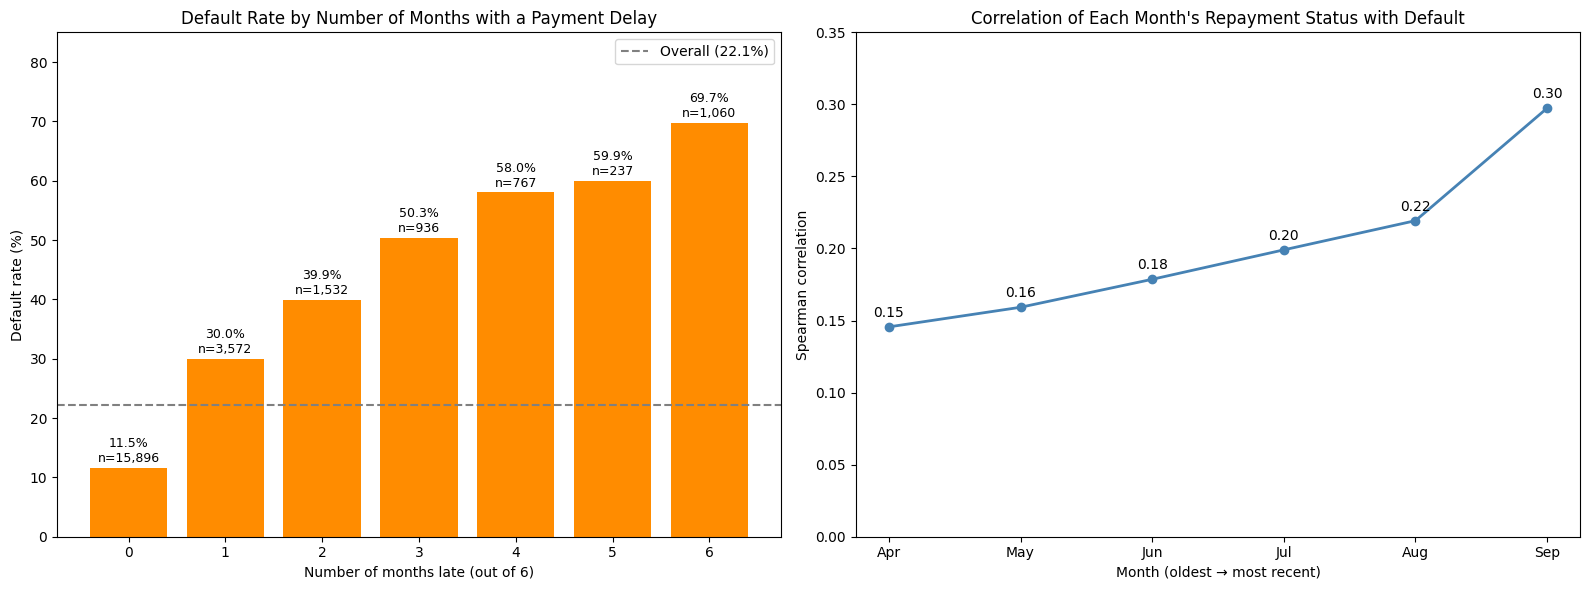

In [ ]:
pay_cols = ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_0"]
months = ["Apr", "May", "Jun", "Jul", "Aug", "Sep"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

months_late = (eda_train[pay_cols] > 0).sum(axis=1)
rate = eda_train.groupby(months_late)[target].mean() * 100
count = months_late.value_counts().sort_index()

axes[0].bar(rate.index, rate.values, color="darkorange")
axes[0].axhline(overall, color="gray", linestyle="--", label=f"Overall ({overall:.1f}%)")
for i, v in zip(rate.index, rate.values):
    axes[0].text(i, v + 1, f"{v:.1f}%\nn={count[i]:,}", ha="center", fontsize=9)
axes[0].set_title("Default Rate by Number of Months with a Payment Delay")
axes[0].set_xlabel("Number of months late (out of 6)")
axes[0].set_ylabel("Default rate (%)")
axes[0].set_ylim(0, 85)
axes[0].legend()

corr = [eda_train[col].corr(eda_train[target], method="spearman") for col in pay_cols]
axes[1].plot(months, corr, marker="o", color="steelblue", linewidth=2)
for m, c in zip(months, corr):
    axes[1].text(m, c + 0.007, f"{c:.2f}", ha="center", fontsize=10)
axes[1].set_title("Correlation of Each Month's Repayment Status with Default")
axes[1].set_xlabel("Month (oldest → most recent)")
axes[1].set_ylabel("Spearman correlation")
axes[1].set_ylim(0, 0.35)

plt.tight_layout()
plt.show()

**Interpretation:**

**Left plot:** The default rate increases steadily with the number of months in which a client was late. Clients with no delays in the six months have a default rate of only **11.5%**, compared to **50.3%** for clients late in 3 months and **69.7%** for clients late in all 6 months. This shows that **repeated delays** are a strong warning sign, not only a single late payment.

**Right plot:** The correlation between repayment status and default becomes stronger for more recent months, rising from **0.15 in April** to **0.30 in September**. This confirms that **recent payment behavior is more informative than older behavior**, which explains why PAY_0 (September) is the strongest repayment feature.



In [ ]:
import seaborn as sns

corr = eda_train.corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5)
plt.title("Spearman Correlation Heatmap (Training Set)", fontsize=15)
plt.show()

ModuleNotFoundError: No module named 'seaborn'

**Interpretation:**

The heatmap shows the Spearman correlation between all features and the target. Spearman was used instead of Pearson because it is rank-based, which suits the ordinal repayment-status codes (PAY_0 to PAY_6) and is less affected by the extreme values seen in the monetary features. Unlike the Pearson analysis in Section 4.6, this heatmap includes all 23 features.

**Correlation with default (last row):**
- **Repayment status** has the strongest positive correlation with default, led by **PAY_0 (0.30)** and decreasing for older months (down to 0.15 for PAY_6).
- **LIMIT_BAL (-0.18)** and **payment amounts PAY_AMT1-6 (about -0.12 to -0.16)** have negative correlations, meaning higher credit limits and larger payments are linked to lower default risk.
- **Bill amounts, AGE, SEX, EDUCATION, and MARRIAGE** are close to zero, showing almost no direct relationship with default.

**Correlation between features:**
- **BILL_AMT1 to BILL_AMT6** are very highly correlated with each other (**0.73 to 0.91**), so they carry largely the same information.
- **PAY_0 to PAY_6** are also strongly correlated (**0.46 to 0.82**), as clients who delay one month tend to delay the following months too.
- **LIMIT_BAL** is negatively correlated with the repayment-status features (about -0.26 to -0.35), meaning clients with higher limits tend to delay payments less.

**Implication:** The strong redundancy among BILL_AMT features suggests they could be combined or reduced during feature engineering. However, correlation only measures monotonic relationships, so features with low correlation are not removed based on this alone.

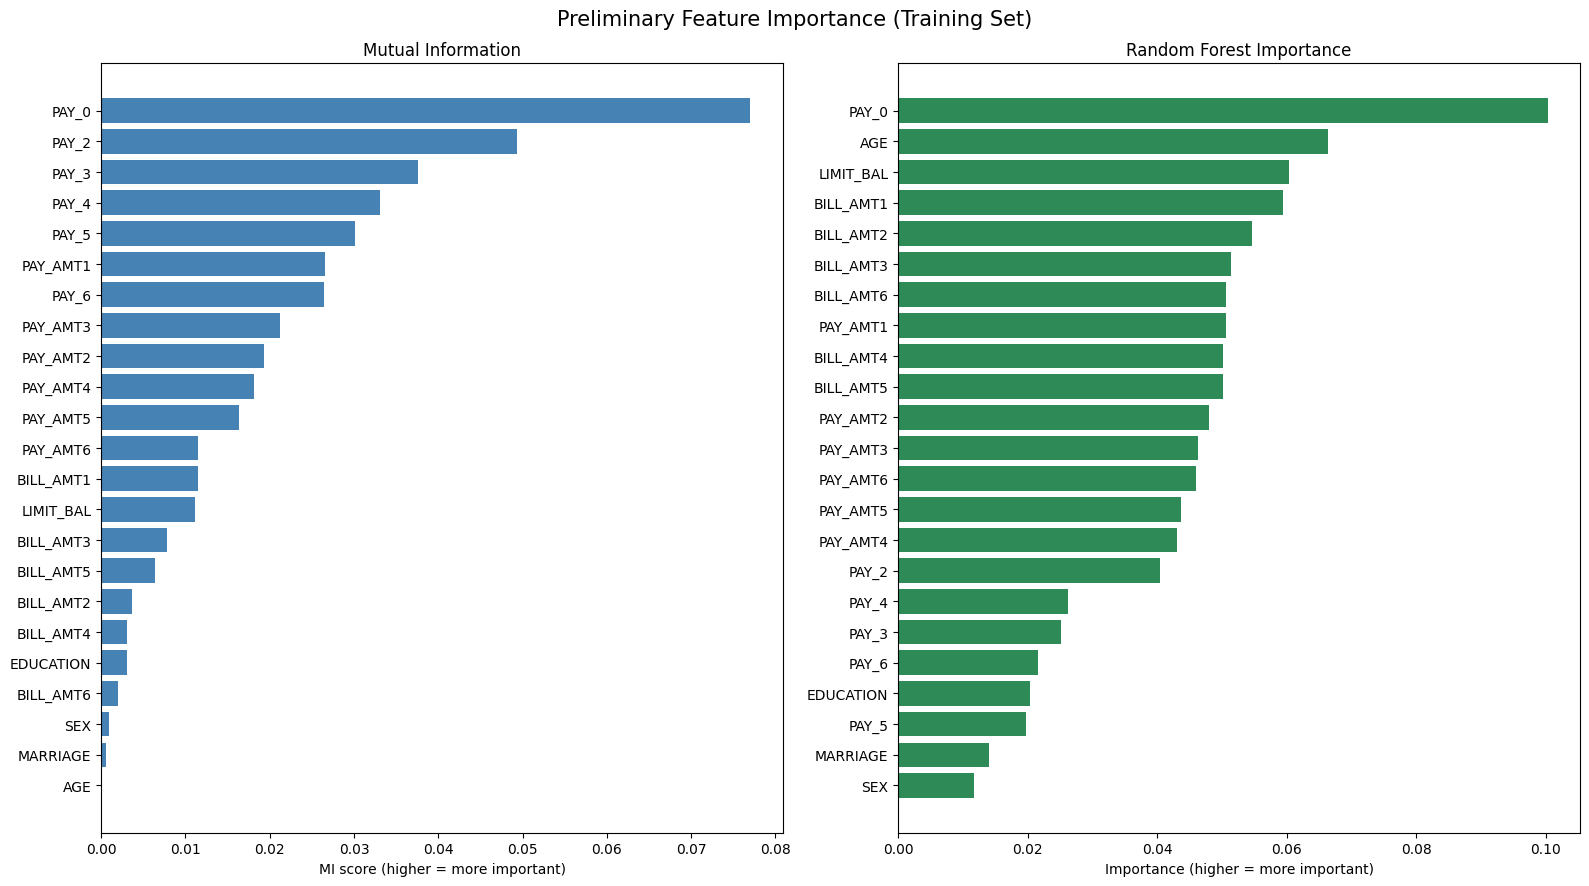

In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

is_category = [col in categorical_features for col in X_train.columns]

#  1: Mutual Information
mi = mutual_info_classif(X_train, y_train, discrete_features=is_category, random_state=42)
mi = pd.Series(mi, index=X_train.columns).sort_values()

#  2: Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 9))

axes[0].barh(mi.index, mi.values, color="steelblue")
axes[0].set_title("Mutual Information")
axes[0].set_xlabel("MI score (higher = more important)")

axes[1].barh(rf_imp.index, rf_imp.values, color="seagreen")
axes[1].set_title("Random Forest Importance")
axes[1].set_xlabel("Importance (higher = more important)")

plt.suptitle("Preliminary Feature Importance (Training Set)", fontsize=15)
plt.tight_layout()
plt.show()

**Interpretation:**

Two methods were used to estimate feature importance on the training set: **Mutual Information (MI)**, which measures how much each feature alone tells us about default, and **Random Forest importance**, which measures how much each feature is used by a tree-based model.

**Where the methods agree:**
- **PAY_0 is the most important feature in both methods**, with a clear gap from the rest. This confirms the earlier visual findings.
- **SEX, MARRIAGE, and EDUCATION are among the least important features in both methods.**

**Where the methods disagree:**
- **AGE** ranks last in MI but second in Random Forest. All other evidence shows that age is weak: its correlation with default is 0.00, and both classes have the same median age (34). Random Forest importance is known to favor features with many unique values, because they offer more possible split points, some of which help only by chance. The same bias explains the relatively high ranking of the **BILL_AMT** features in Random Forest.
- **PAY_2 to PAY_6** rank high in MI but lower in Random Forest. Since these features are strongly correlated with PAY_0, the model gains little extra information from them once PAY_0 is used, while MI evaluates each feature independently.

**Preliminary ranking (combining all evidence):**
1. **Strongest:** PAY_0
2. **Useful:** Other repayment-status features (PAY_2 to PAY_6), LIMIT_BAL, and payment amounts (PAY_AMT1 to PAY_AMT6)
3. **Weak or redundant:** Bill amounts (highly correlated with each other), AGE, SEX, EDUCATION, and MARRIAGE

This ranking is preliminary. Final feature importance will be confirmed by the tuned supervised models in Part B.

# 5. Preprocessing Pipeline

In this section, we prepare the dataset for machine learning. We will review the findings from the initial inspection and EDA, decide which preprocessing steps are necessary, and explain the reason for each decision. The preprocessing pipeline will be designed to avoid data leakage during model training and evaluation.


### 5.1 Drop sensitive features

In [ ]:
sensitive_features = ["SEX", "MARRIAGE"]

X_train = X_train.drop(columns=sensitive_features)
X_test = X_test.drop(columns=sensitive_features)

#update categorical features list
categorical_features = [col for col in categorical_features if col not in sensitive_features]

print("Removed features:", sensitive_features)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Removed features: ['SEX', 'MARRIAGE']
Training set: (24000, 21)
Test set: (6000, 21)


**Justification:**  



*   Fairness: SEX and MARRIAGE are dropped to avoid unfair credit decisions based on gender or marital status.

*   Both features had low preliminary importance scores. The effect of removing them on predictive performance has not been measured.

*   Although EDUCATION and AGE may also introduce some bias, they were kept because they are commonly used in credit assessment.

### 5.2 Feature Engineering

In [ ]:
def add_features(data):
    data = data.copy()
    pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

    # number of months (out of 6) with a payment delay
    data["MONTHS_LATE"] = (data[pay_cols] > 0).sum(axis=1)

    # share of the credit limit used in the most recent bill
    data["UTILIZATION"] = data["BILL_AMT1"] / data["LIMIT_BAL"]

    return data

X_train = add_features(X_train)
X_test = add_features(X_test)

numerical_features = numerical_features + ["MONTHS_LATE", "UTILIZATION"]

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (24000, 23)
Test set: (6000, 23)


**Justification:**  



*   MONTHS_LATE summarizes repayment history in one value. The EDA showed the default rate rising from 11.5% (no delays) to 69.7% (late every month).

*   UTILIZATION relates the bill to the credit limit, so clients with different limits can be compared fairly. It also combines two raw features into one more meaningful value.

### 5.3 Define column groups

In [ ]:
pay_status = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_amounts = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]
pay_amounts = ["PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]

# one-hot encoding
nominal_cols = ["EDUCATION"]

# log + scaling (no negative values)
log_cols = ["LIMIT_BAL"] + pay_amounts

# signed log + scaling (contains negative values)
signed_log_cols = bill_amounts

# scaling only
scale_cols = ["AGE", "MONTHS_LATE", "UTILIZATION"] + pay_status

# check that every column is assigned to exactly one group
all_groups = nominal_cols + log_cols + signed_log_cols + scale_cols
print("Columns assigned:", len(all_groups), "of", X_train.shape[1])
print("Missing:", set(X_train.columns) - set(all_groups))
print("Duplicated:", len(all_groups) != len(set(all_groups)))

Columns assigned: 23 of 23
Missing: set()
Duplicated: False


**Justification:**  



*   EDUCATION has no natural order, so it is one-hot encoded.

*   PAY_0–PAY_6 are ordered (a higher value means a longer delay), so they are kept as numbers instead of one-hot encoded. Codes -2, -1, and 0 do not follow a strict order, but they all indicate no delay and have similar low default rates (Section 4.8), so treating them as numeric is a reasonable simplification.

*   LIMIT_BAL, PAY_AMT and BILL_AMT are right-skewed (Sections 4.3 and 4.8), with PAY_AMT being the most skewed, so they get a log transform to reduce the effect of extreme values. BILL_AMT uses a signed log because it contains negative values.

### 5.4 Preprocessing pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

# log that also works for negative values
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

preprocessor = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),

    ("log_scale", Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler())
    ]), log_cols),

    ("signed_log_scale", Pipeline([
        ("log", FunctionTransformer(signed_log, feature_names_out="one-to-one")),
        ("scale", StandardScaler())
    ]), signed_log_cols),

    ("scale", StandardScaler(), scale_cols),
], verbose_feature_names_out=False)

preprocessor.set_output(transform="pandas")

ColumnTransformer(transformers=[('onehot',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['EDUCATION']),
                                ('log_scale',
                                 Pipeline(steps=[('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scale', StandardScaler())]),
                                 ['LIMIT_BAL', 'PAY_AMT1', 'PAY_AMT2',
                                  'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5',
                                  'PAY_AMT6']),
                                ('signed_log_sc...
                                 Pipeline(steps=[('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function signed_log at 0x7f84011e5bc0>)),
                                                 ('scale', StandardScaler())]),
                                 ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
                                  'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']),
                                ('scale', StandardScaler(),
                                 ['AGE', 'MONTHS_LATE', 'UTILIZATION', 'PAY_0',
                                  'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5',
                                  'PAY_6'])],
                  verbose_feature_names_out=False)

In [ ]:
# fit on the training set only, then transform test
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Training set:", X_train_prep.shape)
print("Test set:", X_test_prep.shape)

Training set: (24000, 29)
Test set: (6000, 29)


**Justification:**  



*   All numeric features are standardized (z-score) because they are on very different scales, which matters for scale-sensitive models such as SVM.

*   handle_unknown="ignore" prevents errors if a rare EDUCATION code appears in the test set but not in training.

*   The preprocessor is fitted on the training set only, which prevents data leakage.

# 6. Preprocessed Dataset Ready for Modeling

In this section, we verify that the preprocessing steps have been applied correctly and that the data is organized for the modeling phase. We will confirm the feature and target shapes, review the final feature types, and ensure that the dataset is ready for the next phase.


### 6.1 Verify preprocessed data

In [ ]:
# confirm feature and target shape, and feature data type
print("Training set:", X_train_prep.shape)
print("Test set:", X_test_prep.shape)
print("Feature types:", X_train_prep.dtypes.value_counts().to_dict())
print("\nTarget (train, test):", y_train.shape, y_test.shape)
print("Default rate (train, test):", round(y_train.mean(), 4), round(y_test.mean(), 4))

print("\nMissing values (train, test):", X_train_prep.isna().sum().sum(), X_test_prep.isna().sum().sum())
print("Row order preserved:", (X_train_prep.index == X_train.index).all())

print("\nFinal features:")
print(X_train_prep.columns.tolist())

display(X_train_prep.describe().T[["mean", "std", "min", "max"]].round(2))

Training set: (24000, 29)
Test set: (6000, 29)
Feature types: {dtype('float64'): 29}

Target (train, test): (24000,) (6000,)
Default rate (train, test): 0.2212 0.2212

Missing values (train, test): 0 0
Row order preserved: True

Final features:
['EDUCATION_0', 'EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'EDUCATION_5', 'EDUCATION_6', 'LIMIT_BAL', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'AGE', 'MONTHS_LATE', 'UTILIZATION', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']


,mean,std,min,max
EDUCATION_0,0.00,0.02,0.00,1.00
EDUCATION_1,0.35,0.48,0.00,1.00
EDUCATION_2,0.47,0.50,0.00,1.00
EDUCATION_3,0.16,0.37,0.00,1.00
EDUCATION_4,0.00,0.06,0.00,1.00
EDUCATION_5,0.01,0.10,0.00,1.00
EDUCATION_6,0.00,0.04,0.00,1.00
LIMIT_BAL,-0.00,1.00,-2.61,2.29
PAY_AMT1,-0.00,1.00,-2.05,2.17
PAY_AMT2,0.00,1.00,-2.00,2.27


*   The final dataset has 29 features: 24,000 rows in the training set and 6,000 rows in the test set.
*   There are no missing values after preprocessing, and the row order is preserved.
*   The default rate is the same in both sets (about 22.1%) because of the stratified split.
*   All features are numeric.
*   The EDUCATION one-hot encoded columns correctly have a min of 0 and a max of 1.
*   The other columns are standardized to a mean of 0 and a standard deviation of 1, so the data is ready for modeling.

### 6.2 Save processed dataset

In [ ]:
train_out = X_train_prep.copy()
train_out.insert(0, "ID", df.loc[X_train_prep.index, "ID"])
train_out[target] = y_train
train_out["split"] = "train"

test_out = X_test_prep.copy()
test_out.insert(0, "ID", df.loc[X_test_prep.index, "ID"])
test_out[target] = y_test
test_out["split"] = "test"

preprocessed = pd.concat([train_out, test_out])
preprocessed.to_csv("Dataset/preprocessed_data.csv", index=False)

print("Saved:", preprocessed.shape)
print(preprocessed["split"].value_counts())

Saved: (30000, 32)
split
train    24000
test      6000
Name: count, dtype: int64


**Justification:**  



*   Train and test rows are saved in one file with a split column, so the supervised models use exactly the same split.

*   ID is kept only to link each row back to the raw dataset; it is not a model input.

*   Before model training, the ID and split columns must be removed so that only the 29 preprocessed features are used as inputs.

# 7. Key Insights & Challenges

This section summarizes the main findings from the data exploration and preprocessing stages. It also discusses the challenges identified in the dataset, the preprocessing decisions made to address them, and any remaining limitations that may affect model development.

**Key Insights:**

*   **Repayment status is the strongest predictor.** PAY_0 ranked first in both Mutual Information and Random Forest importance. Clients who paid on time or made the minimum payment have default rates of about 13–17%, compared to 69.4% for clients who are 2 months late (Section 4.8).

*   **Repeated delays are a strong warning sign.** Clients with no delays in the six months have a default rate of 11.5%, compared to 69.7% for clients who were late in all six months.

*   **Recent behavior matters more than older behavior.** The correlation between repayment status and default rises from 0.15 in April to 0.30 in September.

*   **Credit limit and payment amounts are useful predictors.** Default clients have a lower median credit limit (90,000 vs 150,000) and lower payment amounts across all six months.

*   **Demographic features are weak predictors.** SEX, MARRIAGE, and EDUCATION have low preliminary importance scores. AGE has low mutual information but high Random Forest impurity importance, so its predictive contribution requires further validation.

*   **Bill amounts are highly redundant.** BILL_AMT1 to BILL_AMT6 are strongly correlated with each other (0.803 to 0.952), so they carry largely the same information.

**Challenges:**

*   **Class imbalance:**

    The target is imbalanced (77.88% non-default and 22.12% default). A stratified split was used to keep the same ratio in both sets, and models will be evaluated using precision, recall, and F1-score in addition to accuracy.

*   **Skewed features and extreme values:**

    Monetary features are right-skewed, with many extreme values. Instead of removing these values, a log transformation (signed log for BILL_AMT, which contains negative values) and standardization were applied (Section 5).

*   **Undocumented category codes:**

    EDUCATION codes 0, 5, and 6 and MARRIAGE code 0 are not defined in the original documentation. They affect only a small share of clients (about 1.2% and 0.2%). The EDUCATION codes were kept as separate categories instead of being given an unsupported meaning, while MARRIAGE was later removed for fairness reasons (Section 5.1).

*   **Repeated rows:**

    There are 26 repeated rows in the training set when ID is excluded. They were retained because identical profiles do not prove that they belong to the same client.

*   **Fairness:**

    In Section 5.1, SEX and MARRIAGE were dropped to reduce bias in the model. However, this does not fully guarantee fairness.

    Features such as EDUCATION, AGE, and LIMIT_BAL were kept, as they are used in practice for credit assessments, but they may still be indirectly linked to the dropped attributes, so the model could show some bias.

**Remaining Limitations:**

*   The dataset comes from a single source in Taiwan, so the results may not generalize to other countries or time periods.
*   The meaning of some codes (such as PAY codes -2 and 0) is not officially documented, so their interpretation is based on common understanding.
*   The feature importance results are preliminary and will be confirmed by the supervised models in Part B.